In [37]:
import pandas as pd
import numpy as np
import tensorflow as tf

from tensorflow.keras.preprocessing import text
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.utils import to_categorical, pad_sequences
from tensorflow.keras import backend as K
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Embedding, Lambda

from sklearn.metrics.pairwise import euclidean_distances
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import Embedding, LSTM, Dense
import matplotlib.pyplot as plt

In [26]:
data = [
    "Natural Language Processing is a field of Artificial Intelligence.",
    "Word embeddings help computers understand human language.",
    "The CBOW model is a part of Word2Vec technique.",
    "CBOW predicts the target word using surrounding context words.",
    "Skip Gram is another architecture of Word2Vec.",
    "Word2Vec is widely used in NLP applications.",
    "Embedding layers in deep learning represent words as vectors.",
    "CBOW is faster and works better with frequent words.",
    "Machine learning helps computers learn from data.",
    "Deep learning uses neural networks to learn complex patterns.",
    "Artificial intelligence is changing the world.",
    "Natural language processing helps computers process text.",
    "A neural network contains input hidden and output layers.",
    "The model learns patterns from the training data.",
    "Data preprocessing is an important step in machine learning.",
    "Text data is converted into numerical sequences.",
    "Tokenization splits text into individual words.",
    "A tokenizer assigns an integer to every unique word.",
    "Word prediction models learn from previous words.",
    "The next word depends on the words before it.",
    "Deep learning models need enough training examples.",
    "A large dataset can help the model learn more patterns.",
    "The computer can predict words using language context.",
    "Python is widely used for artificial intelligence.",
    "TensorFlow is a popular deep learning library.",
    "Keras makes it easier to build neural networks.",
    "The embedding layer converts words into dense vectors.",
    "The LSTM network can learn sequences of words.",
    "Training adjusts model weights to reduce prediction error.",
    "The model predicts the most likely next word.",
    "Natural language processing is used in chatbots.",
    "Chatbots answer questions using language technology.",
    "A sentence contains words arranged in a sequence.",
    "The training process repeats over multiple epochs.",
    "Model accuracy shows how often predictions are correct.",
    "The context of a sentence helps determine word meaning.",
    "Word2Vec learns useful representations of words.",
    "CBOW uses context words to predict a target word.",
    "Skip Gram predicts context words from a target word.",
    "Language models can generate text one word at a time."
]

print("Total sentences:", len(data))

Total sentences: 40


In [27]:
tokenizer = Tokenizer()
tokenizer.fit_on_texts(data)

word2id = tokenizer.word_index
word2id["PAD"] = 0

id2word = {index: word for word, index in word2id.items()}

wids = tokenizer.texts_to_sequences(data)

vocab_size = len(word2id)
embed_size = 100
window_size = 2

print("Vocabulary Size:", vocab_size)
print("Sample Vocabulary:", list(word2id.items())[:15])
print("Sample Sequence:", wids[0])

Vocabulary Size: 150
Sample Vocabulary: [('the', 1), ('words', 2), ('a', 3), ('is', 4), ('word', 5), ('language', 6), ('of', 7), ('model', 8), ('learning', 9), ('context', 10), ('in', 11), ('learn', 12), ('to', 13), ('cbow', 14), ('word2vec', 15)]
Sample Sequence: [22, 6, 23, 4, 3, 59, 7, 24, 25]


In [28]:
# Display word-to-ID and ID-to-word lookup tables
lookup_table = pd.DataFrame(
    [(word, word_id) for word, word_id in word2id.items()],
    columns=["Word", "Word ID"]
).sort_values("Word ID").reset_index(drop=True)

print("Word-to-ID Lookup Table")
display(lookup_table)

reverse_lookup_table = pd.DataFrame(
    [(word_id, word) for word_id, word in id2word.items()],
    columns=["Word ID", "Word"]
).sort_values("Word ID").reset_index(drop=True)

print("ID-to-Word Lookup Table")
display(reverse_lookup_table)

Word-to-ID Lookup Table


,Word,Word ID
0,PAD,0
1,the,1
2,words,2
3,a,3
4,is,4
...,...,...
145,representations,145
146,generate,146
147,one,147
148,at,148


ID-to-Word Lookup Table


,Word ID,Word
0,0,PAD
1,1,the
2,2,words
3,3,a
4,4,is
...,...,...
145,145,representations
146,146,generate
147,147,one
148,148,at


In [29]:
# B. Generate Training Data
def generate_data(sequences, window_size, vocab_size):
    X = []
    Y = []

    for sequence in sequences:
        for i, target in enumerate(sequence):

            # Get context words around the target word
            start = max(0, i - window_size)
            end = min(len(sequence), i + window_size + 1)

            context = [sequence[j] for j in range(start, end) if j != i]

            if context:
                X.append(context)
                Y.append(target)

    return X, Y


X, Y = generate_data(wids, window_size, vocab_size)

print("Total training samples:", len(X))

print("\nSample context IDs:", X[1])
print("Sample context words:", [id2word[id] for id in X[1]])

print("Sample target ID:", Y[1])
print("Sample target word:", id2word[Y[1]])

Total training samples: 317

Sample context IDs: [22, 23, 4]
Sample context words: ['natural', 'processing', 'is']
Sample target ID: 6
Sample target word: language


In [30]:
# Make all context sequences the same length
X = pad_sequences(X, maxlen=window_size * 2, padding="post", value=0)

Y = np.array(Y)

print("Input shape:", X.shape)
print("Target shape:", Y.shape)
print("\nFirst context:", X[0])
print("First target:", Y[0])

Input shape: (317, 4)
Target shape: (317,)

First context: [ 6 23  0  0]
First target: 22


In [31]:
# Display context-target training examples as a table
training_rows = []

for i in range(len(X)):
    context_ids = [int(word_id) for word_id in X[i] if word_id != 0]
    target_id = int(Y[i])

    training_rows.append({
        "Context IDs": context_ids,
        "Context Words": [id2word[word_id] for word_id in context_ids],
        "Target ID": target_id,
        "Target Word": id2word[target_id]
    })

training_table = pd.DataFrame(training_rows)

print("Context-Target Training Table (first 15 examples)")
display(training_table.head(15))


Context-Target Training Table (first 15 examples)


,Context IDs,Context Words,Target ID,Target Word
0,"[6, 23]","[language, processing]",22,natural
1,"[22, 23, 4]","[natural, processing, is]",6,language
2,"[22, 6, 4, 3]","[natural, language, is, a]",23,processing
3,"[6, 23, 3, 59]","[language, processing, a, field]",4,is
4,"[23, 4, 59, 7]","[processing, is, field, of]",3,a
5,"[4, 3, 7, 24]","[is, a, of, artificial]",59,field
6,"[3, 59, 24, 25]","[a, field, artificial, intelligence]",7,of
7,"[59, 7, 25]","[field, of, intelligence]",24,artificial
8,"[7, 24]","[of, artificial]",25,intelligence
9,"[60, 36]","[embeddings, help]",5,word


In [32]:
# C. Build and Train the CBOW Model
cbow = Sequential([
    # Convert word IDs into embedding vectors
    Embedding(
        input_dim=vocab_size,
        output_dim=embed_size,
        input_length=window_size * 2
    ),

    # Calculate the average of the context word embeddings
    Lambda(lambda x: K.mean(x, axis=1)),

    # Predict the target word
    Dense(vocab_size, activation="softmax")
])

# Compile the model
cbow.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

# Display model architecture
cbow.summary()

C:\Users\Admin\anaconda3\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)              │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lambda_2 (Lambda)                    │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [34]:
# Train the model
history = cbow.fit(
    X,
    Y,
    epochs=100,
    batch_size=16,
    verbose=1
)

Epoch 1/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.0379 - loss: 5.0054    
Epoch 2/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1356 - loss: 4.9746 
Epoch 3/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1767 - loss: 4.9437 
Epoch 4/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1861 - loss: 4.9067 
Epoch 5/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1830 - loss: 4.8577 
Epoch 6/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1861 - loss: 4.7964 
Epoch 7/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1861 - loss: 4.7219 
Epoch 8/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1798 - loss: 4.6360 
Epoch 9/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1735 - loss: 4.5419 
Epoch 10/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1640 - loss: 4.4536 
Epoch 11/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1735 - loss: 4.3700 
Epoch 12/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/st

In [35]:
# Compare prediction and loss AFTER training
after_prediction = cbow.predict(X[:1], verbose=0)[0]
after_loss = cbow.evaluate(X, Y, verbose=0)[0]
after_predicted_id = int(np.argmax(after_prediction))

print("Sample context words:", [id2word[int(w)] for w in X[0] if w != 0])
print("Actual target:", id2word[int(Y[0])])
print("Prediction AFTER training:", id2word.get(after_predicted_id, "Unknown"))
print("Highest probability AFTER training:", round(float(np.max(after_prediction)) * 100, 2), "%")
print("Loss AFTER training:", round(float(after_loss), 4))

# Display the embedding lookup table AFTER training
trained_embedding_weights = cbow.get_weights()[0]

trained_embedding_table = pd.DataFrame(
    trained_embedding_weights,
    index=[id2word.get(i, "Unknown") for i in range(vocab_size)],
    columns=[f"Dim_{i+1}" for i in range(embed_size)]
)
trained_embedding_table.index.name = "Word"

print("Embedding lookup table AFTER training (first 10 rows)")
display(trained_embedding_table.head(10))


Sample context words: ['language', 'processing']
Actual target: natural
Prediction AFTER training: natural
Highest probability AFTER training: 88.6 %
Loss AFTER training: 0.2424
Embedding lookup table AFTER training (first 10 rows)


,Dim_1,Dim_2,Dim_3,Dim_4,Dim_5,Dim_6,Dim_7,Dim_8,Dim_9,Dim_10,...,Dim_91,Dim_92,Dim_93,Dim_94,Dim_95,Dim_96,Dim_97,Dim_98,Dim_99,Dim_100
Word,,,,,,,,,,,,,,,,,,,,,
PAD,0.235525,0.511287,-0.309429,0.147134,0.298630,-0.499869,-0.154213,-0.241828,-0.125102,0.167106,...,0.835039,-0.491331,-1.199370,-0.052861,0.246901,-0.510792,0.396835,-0.280260,-0.158796,-0.829980
the,0.520284,-0.084967,0.239161,0.200669,0.531321,0.156719,0.172245,1.090945,-1.025331,0.583966,...,-0.280470,-0.530239,0.292436,-0.036531,-0.129253,0.209779,-0.504714,0.029613,0.693086,-0.039832
words,-0.666147,0.020039,-0.254244,-0.764402,0.534783,0.837547,-0.329814,0.062043,0.383025,0.411219,...,-0.810861,-0.749190,0.581457,-0.182964,0.572023,-0.325843,-0.961787,0.448894,-0.460474,0.812489
a,-0.610024,1.127723,0.315488,-0.237390,-0.006115,0.804764,0.810452,-0.040331,-0.219257,0.090117,...,-0.922735,-0.615373,1.422411,0.855164,-1.040798,-0.251606,0.438836,-0.468374,0.175692,-0.491683
is,0.177709,-0.205828,0.013795,-0.203237,-0.775538,-0.505612,1.037607,-0.828129,0.984044,0.088953,...,-0.343099,0.957572,-0.438282,-0.887856,0.117401,-0.412347,0.206216,-0.202851,0.063431,0.600316
word,0.269592,0.856449,0.376650,0.996409,-0.132776,0.410778,0.541823,0.054631,-0.044212,0.302483,...,0.002589,0.376006,0.036707,0.770802,0.203921,0.901261,-0.498848,0.315751,-0.709730,0.390302
language,-0.389380,0.021349,-0.720635,0.580482,-0.346079,0.906888,0.247064,-0.371186,-0.211971,1.011811,...,-0.270665,-0.562461,0.176080,1.036188,0.540856,0.566051,-0.109563,-0.177975,1.133415,0.347138
of,-0.903810,-0.074018,0.144403,0.188626,-0.239739,-0.309419,0.666307,-0.668037,0.302131,0.088641,...,0.553744,0.504151,-0.626726,-0.892938,0.088269,0.227927,0.046980,-0.060571,-0.679436,0.058936
model,0.269415,0.465813,0.092917,0.166836,0.113712,-0.259594,-0.828531,0.260800,0.935022,-0.356737,...,0.812283,0.165298,-0.258072,0.126415,0.315437,0.088616,-0.787437,0.910375,-0.627675,-1.076404


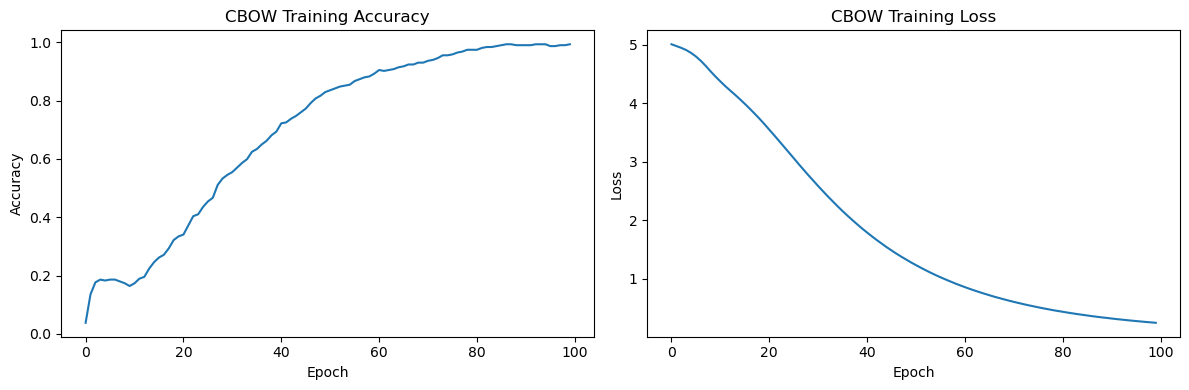

In [38]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"])
plt.title("CBOW Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

# Plot training loss
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"])
plt.title("CBOW Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.tight_layout()
plt.show()

In [39]:
weights = cbow.get_weights()[0]

weights = weights[1:]

# Create a DataFrame of word embeddings
embedding_df = pd.DataFrame(
    weights,
    index=[id2word[i] for i in range(1, vocab_size)]
)

print("Embedding matrix shape:", weights.shape)

display(embedding_df.head(5))

Embedding matrix shape: (149, 100)


,0,1,2,3,4,5,6,7,8,9,...,90,91,92,93,94,95,96,97,98,99
the,0.520284,-0.084967,0.239161,0.200669,0.531321,0.156719,0.172245,1.090945,-1.025331,0.583966,...,-0.280470,-0.530239,0.292436,-0.036531,-0.129253,0.209779,-0.504714,0.029613,0.693086,-0.039832
words,-0.666147,0.020039,-0.254244,-0.764402,0.534783,0.837547,-0.329814,0.062043,0.383025,0.411219,...,-0.810861,-0.749190,0.581457,-0.182964,0.572023,-0.325843,-0.961787,0.448894,-0.460474,0.812489
a,-0.610024,1.127723,0.315488,-0.237390,-0.006115,0.804764,0.810452,-0.040331,-0.219257,0.090117,...,-0.922735,-0.615373,1.422411,0.855164,-1.040798,-0.251606,0.438836,-0.468374,0.175692,-0.491683
is,0.177709,-0.205828,0.013795,-0.203237,-0.775538,-0.505612,1.037607,-0.828129,0.984044,0.088953,...,-0.343099,0.957572,-0.438282,-0.887856,0.117401,-0.412347,0.206216,-0.202851,0.063431,0.600316
word,0.269592,0.856449,0.376650,0.996409,-0.132776,0.410778,0.541823,0.054631,-0.044212,0.302483,...,0.002589,0.376006,0.036707,0.770802,0.203921,0.901261,-0.498848,0.315751,-0.709730,0.390302


In [40]:
# Find 5 similar words for each user-entered word

weights = cbow.get_weights()[0][1:]
distance_matrix = euclidean_distances(weights)

words = input("Enter words separated by spaces: ").lower().split()

for word in words:
    if word in word2id and word2id[word] != 0:
        word_index = word2id[word] - 1
        nearest_indices = distance_matrix[word_index].argsort()[1:6]

        similar_words = [id2word[idx + 1] for idx in nearest_indices]

        print(f"{word}: {similar_words}")
    else:
        print(f"{word}: Word not found in vocabulary.")

Enter words separated by spaces:  natural cbow 


natural: ['technology', 'human', 'understand', 'questions', 'using']
cbow: ['tensorflow', 'popular', 'changing', 'skip', 'python']


In [42]:
next_tokenizer = Tokenizer(oov_token="<OOV>")
next_tokenizer.fit_on_texts(data)
next_word2id = next_tokenizer.word_index
next_id2word = {i: w for w, i in next_word2id.items()}
next_vocab_size = len(next_word2id) + 1

input_sequences = []
for sentence in data:
    token_list = next_tokenizer.texts_to_sequences([sentence.lower()])[0]
    for i in range(1, len(token_list)):
        input_sequences.append(token_list[:i + 1])

max_sequence_len = max(len(seq) for seq in input_sequences)
padded_sequences = pad_sequences(input_sequences, maxlen=max_sequence_len, padding="pre")
X_next = padded_sequences[:, :-1]
y_next = padded_sequences[:, -1]

print("Number of next-word training examples:", len(X_next))
print("Input shape:", X_next.shape)
print("Vocabulary size:", next_vocab_size)


Number of next-word training examples: 277
Input shape: (277, 9)
Vocabulary size: 151


In [43]:
# Build and train the next-word prediction model
next_model = Sequential([
    Embedding(input_dim=next_vocab_size, output_dim=64, input_length=max_sequence_len - 1),
    LSTM(100),
    Dense(next_vocab_size, activation="softmax")
])

next_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

next_history = next_model.fit(
    X_next, y_next,
    epochs=150,
    batch_size=16,
    verbose=1
)


Epoch 1/150


C:\Users\Admin\anaconda3\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.0144 - loss: 5.0138    
Epoch 2/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.0469 - loss: 4.9464
Epoch 3/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.0397 - loss: 4.7884     
Epoch 4/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.0397 - loss: 4.7079 
Epoch 5/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.0505 - loss: 4.6666 
Epoch 6/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.0542 - loss: 4.6338 
Epoch 7/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.0686 - loss: 4.5997 
Epoch 8/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.0794 - loss: 4.5493 
Epoch 9/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.0830 - loss: 4.4645 
Epoch 10/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.0758 - loss: 4.3514 
Epoch 11/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1011 - loss: 4.2515
Epoch 12/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - acc

In [46]:
# Predict the next 1 or 2 words
def predict_next_words(seed_text, number_of_words=1):
    result = seed_text.lower().strip()

    for _ in range(number_of_words):
        token_list = next_tokenizer.texts_to_sequences([result])[0]
        token_list = pad_sequences([token_list], maxlen=max_sequence_len - 1, padding="pre")
        probabilities = next_model.predict(token_list, verbose=0)[0]

        # Avoid predicting the OOV token if possible
        probabilities[0] = 0
        predicted_id = int(np.argmax(probabilities))
        predicted_word = next_id2word.get(predicted_id, "")

        if not predicted_word or predicted_word == "<OOV>":
            break
        result += " " + predicted_word

    return result

seed_text = input("Enter a few words: ")
num_words = int(input("How many words should be predicted? Enter 1 or 2: "))
num_words = max(1, min(num_words, 2))
print("Prediction:", predict_next_words(seed_text, num_words))

Enter a few words:  cbow
How many words should be predicted? Enter 1 or 2:  2


Prediction: cbow uses context
